In [ ]:
from scipy.stats import norm
import numpy as np
import matplotlib.pyplot as plt


In [ ]:
x = np.array([100, 120, 90, 110 , 95, 105, 115, 10000])

In [ ]:
mu = np.mean(x)
sigma = np.std(x)

print('Mean:', mu)
print('Std:', sigma)

Mean: 1341.875
Std: 3272.477021978153


In [ ]:
density = norm.pdf(x, mu, scale=sigma)

In [ ]:
print(density)

[1.13438734e-04 1.13700013e-04 1.13306733e-04 1.13569829e-04
 1.13372847e-04 1.13504395e-04 1.13635035e-04 3.68141852e-06]


In [ ]:
epsilon = 0.00001

In [ ]:
anomalies = x[density < epsilon]

In [ ]:
print('Anomalies:', anomalies)

Anomalies: [10000]


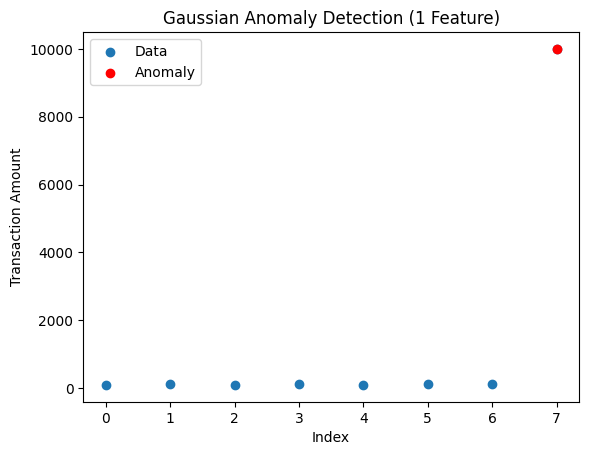

In [ ]:
plt.scatter(range(len(x)), x, label="Data")
plt.scatter(np.where(density < epsilon), anomalies, color="red", label="Anomaly")
plt.title("Gaussian Anomaly Detection (1 Feature)")
plt.xlabel("Index")
plt.ylabel("Transaction Amount")
plt.legend()
plt.show()


In [ ]:
import pandas as pd

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving creditcard.csv to creditcard.csv


In [ ]:
df = pd.read_csv("creditcard.csv")

In [ ]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [ ]:
print("NaN in Amount:", df["Amount"].isna().sum())
print("NaN in Class:", df["Class"].isna().sum())

NaN in Amount: 0
NaN in Class: 0


In [ ]:
#It changes any infinite values in the Amount column into NaN (missing value).
df["Amount"] = df["Amount"].replace([np.inf, -np.inf], np.nan)
df = df.dropna(subset=["Amount"])


In [ ]:
df["Class"] = df["Class"].replace([np.inf, -np.inf], np.nan)
df = df.dropna(subset=["Class"])

In [ ]:
print("NaN in Amount:", df["Amount"].isna().sum())
print("NaN in Class:", df["Class"].isna().sum())

NaN in Amount: 0
NaN in Class: 0


In [ ]:
# Take only Amount feature
amount = df["Amount"].values
y = df["Class"].values

In [ ]:
# gaussian parameters (normal only)
normal_amount = df[df["Class"] == 0]["Amount"].values
mu = np.mean(normal_amount)
sigma = np.std(normal_amount)


In [ ]:
# Train Gaussian on NORMAL only
normal_amount = df[df["Class"] == 0]["Amount"].values

In [ ]:
mu = np.mean(normal_amount)
sigma = np.std(normal_amount)
print("Gaussian Parameters:")
print("mu =", mu)
print("sigma =", sigma)

Gaussian Parameters:
mu = 88.29102242231328
sigma = 250.1046523874876


mu: 88.29102242231328
sigma: 250.1046523874876


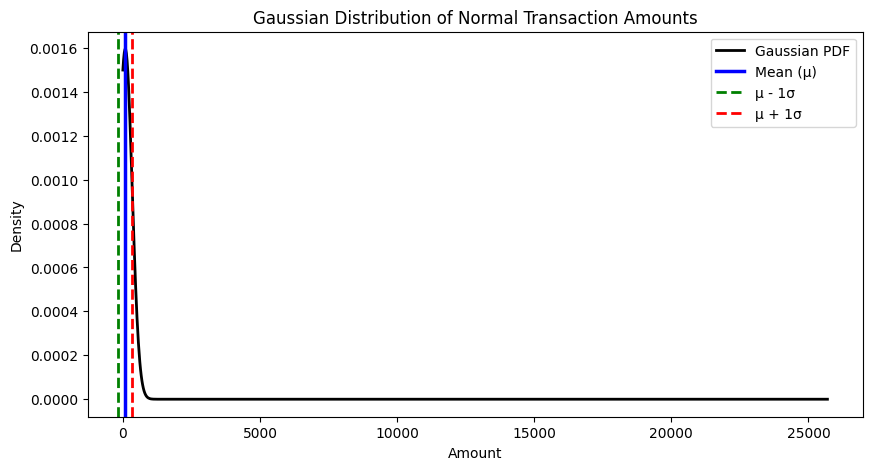

In [ ]:
if sigma == 0:
    sigma = 1e-6

print("mu:", mu)
print("sigma:", sigma)

# ---- Gaussian curve plot ----
x_vals = np.linspace(normal_amount.min(), normal_amount.max(), 1000)
pdf_vals = norm.pdf(x_vals, loc=mu, scale=sigma)

plt.figure(figsize=(10,5))

# main curve
plt.plot(x_vals, pdf_vals, color="black", linewidth=2, label="Gaussian PDF")

# mean line
plt.axvline(mu, color="blue", linestyle="-", linewidth=2.5, label="Mean (μ)")

# mu - sigma line
plt.axvline(mu - sigma, color="green", linestyle="--", linewidth=2, label="μ - 1σ")

# mu + sigma line
plt.axvline(mu + sigma, color="red", linestyle="--", linewidth=2, label="μ + 1σ")

plt.title("Gaussian Distribution of Normal Transaction Amounts")
plt.xlabel("Amount")
plt.ylabel("Density")
plt.legend()
plt.show()


In [ ]:
# Density score for each transaction
density = norm.pdf(amount, loc=mu, scale=sigma)

In [ ]:
# Choose epsilon using percentile (easy)
epsilon = np.percentile(density, 1)  # lowest 1% as anomaly


In [ ]:
# Predict anomaly
y_pred = (density < epsilon).astype(int)

In [ ]:
print("Epsilon:", epsilon)
print("Total anomalies predicted:", np.sum(y_pred))

Epsilon: 1.5936950905276298e-06
Total anomalies predicted: 2849


In [ ]:
# Show some detected anomalies
detected = df[y_pred == 1][["Amount", "Class"]].head(10)
print(detected)

       Amount  Class
51    1402.95      0
89    1142.02      0
164   3828.04      0
865   1602.99      0
1027  1528.90      0
1281  1736.00      0
1388  2452.03      0
1425  1376.13      0
1632  7712.43      0
1641  1127.78      0


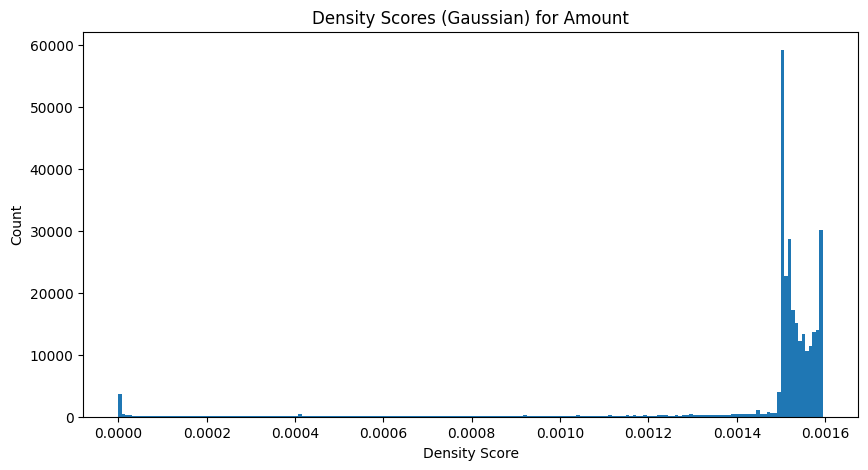

In [ ]:
# Plot density distribution
plt.figure(figsize=(10,5))
plt.hist(density, bins=200)
plt.title("Density Scores (Gaussian) for Amount")
plt.xlabel("Density Score")
plt.ylabel("Count")
plt.show()

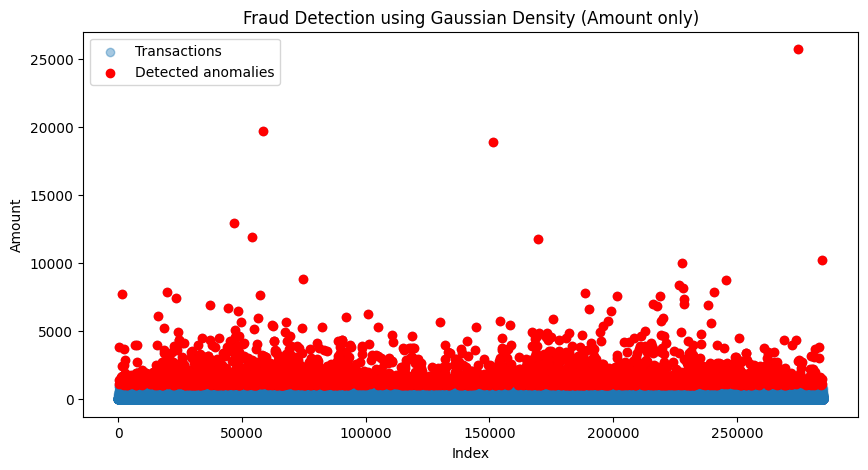

In [ ]:
# Plot Amount with anomalies
plt.figure(figsize=(10,5))
plt.scatter(range(len(amount)), amount, alpha=0.4, label="Transactions")
plt.scatter(np.where(y_pred == 1)[0], amount[y_pred == 1], color="red", label="Detected anomalies")
plt.title("Fraud Detection using Gaussian Density (Amount only)")
plt.xlabel("Index")
plt.ylabel("Amount")
plt.legend()
plt.show()

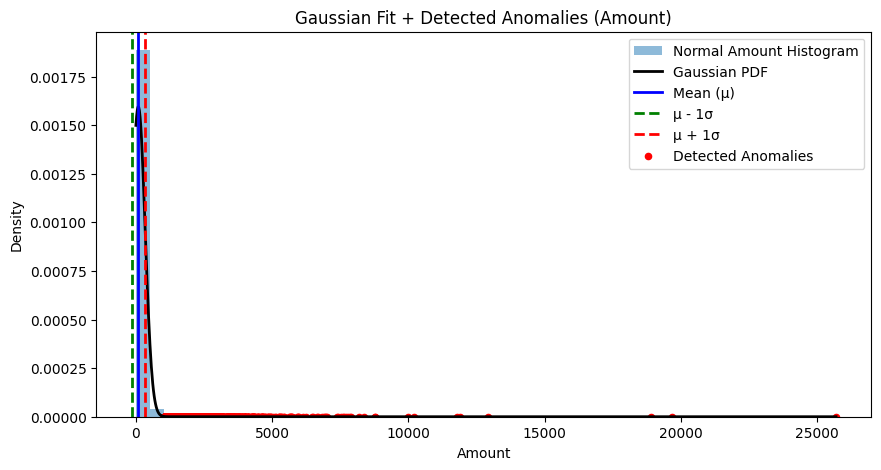

In [ ]:
anomaly_amounts = amount[y_pred == 1]

plt.figure(figsize=(10,5))

# Histogram of normal amounts
plt.hist(normal_amount, bins=50, density=True, alpha=0.5, label="Normal Amount Histogram")

# Gaussian curve
x_vals = np.linspace(normal_amount.min(), normal_amount.max(), 1000)
pdf_vals = norm.pdf(x_vals, loc=mu, scale=sigma)
plt.plot(x_vals, pdf_vals, color="black", linewidth=2, label="Gaussian PDF")

# Mean and std lines
plt.axvline(mu, color="blue", linestyle="-", linewidth=2, label="Mean (μ)")
plt.axvline(mu - sigma, color="green", linestyle="--", linewidth=2, label="μ - 1σ")
plt.axvline(mu + sigma, color="red", linestyle="--", linewidth=2, label="μ + 1σ")

# Plot anomalies on x-axis (near 0 density line)
plt.scatter(anomaly_amounts, np.zeros_like(anomaly_amounts),
            color="red", s=20, label="Detected Anomalies")

plt.title("Gaussian Fit + Detected Anomalies (Amount)")
plt.xlabel("Amount")
plt.ylabel("Density")
plt.legend()
plt.show()


In [ ]:
!pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 67.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 117.2 MB/s eta 0:00:00


In [ ]:
import streamlit as st

In [ ]:
st.title("Regestration System")

2026-01-24 13:55:23.398 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-01-24 13:55:23.593 
  command:

    streamlit run /usr/local/lib/python3.12/dist-packages/colab_kernel_launcher.py [ARGUMENTS]
2026-01-24 13:55:23.594 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-01-24 13:55:23.596 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


DeltaGenerator()

In [ ]:
st.write("Welcome to the regestration sysytem. Please fill in your details below")

2026-01-24 13:57:00.292 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-01-24 13:57:00.294 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-01-24 13:57:00.295 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
